# Day 2 — Supervised Machine Learning

## Predicting Annual Residential Gas Consumption

### Objective

Develop and evaluate supervised machine learning regression models to predict annual residential gas consumption for 2024.

### Dataset

The cleaned residential energy dataset prepared during Day 1.

### Target

`Gcons2024` — annual gas consumption in 2024, measured in kWh.

### Method

1. Inspect the dataset and define the prediction features.
2. Split the data into training and test sets.
3. Build preprocessing pipelines.
4. Establish a baseline model.
5. Train and compare multiple regression models using five-fold cross-validation.
6. Tune a candidate model and evaluate it on the held-out test set.
7. Interpret model performance and prediction errors.
8. Save the complete model pipeline and document the results.


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
import joblib   # to save and load trained models

# Display more columns when inspecting the dataset
pd.set_option("display.max_columns", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Dataset

We will load the cleaned dataset prepared during Day 1.

Before training any models, we need to understand:

* The number of rows and columns.
* The available features.
* The data types.
* A sample of the dataset.


In [2]:
# Load the cleaned dataset
df = pd.read_csv("../data/anon2026_50k_cleaned.csv")

# Display basic information
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn data types:")
display(df.dtypes)

Dataset shape: (49998, 96)

First five rows:


,PROP_TYPE,PROP_AGE_BAND,FLOOR_AREA_BAND,CONSERVATORY_FLAG,COUNCIL_TAX_BAND,IMD_BAND_ENG,IMD_BAND_WALES,REGION,EPC,LI_FLAG,LI_DATE,CWI_FLAG,CWI_DATE,PV_FLAG,PV_DATE,MAIN_HEAT_FUEL,Gcons2024,Gcons2023,Gcons2022,Gcons2021,Gcons2020,Gcons2019,Gcons2018,Gcons2017,Gcons2016,Gcons2015,Gcons2014,Gcons2013,Gcons2012,Gcons2011,Gcons2010,Gcons2009,Gcons2008,Gcons2007,Gcons2006,Gcons2005,GasValFlag2024,GasValFlag2023,GasValFlag2022,GasValFlag2021,GasValFlag2020,GasValFlag2019,GasValFlag2018,GasValFlag2017,GasValFlag2016,GasValFlag2015,GasValFlag2014,GasValFlag2013,GasValFlag2012,GasValFlag2011,GasValFlag2010,GasValFlag2009,GasValFlag2008,GasValFlag2007,GasValFlag2006,GasValFlag2005,Econs2024,Econs2023,Econs2022,Econs2021,Econs2020,Econs2019,Econs2018,Econs2017,Econs2016,Econs2015,Econs2014,Econs2013,Econs2012,Econs2011,Econs2010,Econs2009,Econs2008,Econs2007,Econs2006,Econs2005,ElecValFlag2024,ElecValFlag2023,ElecValFlag2022,ElecValFlag2021,ElecValFlag2020,ElecValFlag2019,ElecValFlag2018,ElecValFlag2017,ElecValFlag2016,ElecValFlag2015,ElecValFlag2014,ElecValFlag2013,ElecValFlag2012,ElecValFlag2011,ElecValFlag2010,ElecValFlag2009,ElecValFlag2008,ElecValFlag2007,ElecValFlag2006,ElecValFlag2005
0,Semi detached,3,2,NaN,A,3.0,NaN,E12000004,C,0,NaN,0,NaN,0,NaN,1,6600.0,6600.0,5500.0,6600.0,7400.0,7400.0,9600.0,9600.0,6700.0,8300.0,8800.0,8600.0,12100.0,10800.0,12400.0,12800.0,13400.0,16000.0,14400.0,14400.0,E,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,E,E,3100.0,2700.0,2800.0,2800.0,2100.0,1700.0,2200.0,NaN,2100.0,2800.0,3300.0,4200.0,700.0,3800.0,2700.0,1000.0,NaN,1600.0,2300.0,2200.0,V,V,V,V,V,V,V,L,V,V,V,V,V,V,V,V,L,V,V,V
1,Mid terrace,1,3,NaN,E,1.0,NaN,E12000007,No EPC,0,NaN,0,NaN,0,NaN,1,13500.0,14100.0,12500.0,13900.0,16900.0,17000.0,15100.0,16500.0,17400.0,17500.0,17000.0,16800.0,16600.0,16800.0,18000.0,16600.0,18200.0,18300.0,16600.0,16600.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,4200.0,2300.0,1700.0,2200.0,2800.0,2900.0,2300.0,2300.0,2700.0,3100.0,2900.0,2700.0,3000.0,3800.0,4100.0,4500.0,4100.0,4500.0,4800.0,3900.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V
2,Detached,4,3,0.0,E,3.0,NaN,E12000005,A/B,0,NaN,0,NaN,0,NaN,1,9700.0,7100.0,7100.0,10100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,E,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,2400.0,2300.0,2000.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
3,Semi detached,4,2,0.0,C,4.0,NaN,E12000004,A/B,0,NaN,0,NaN,0,NaN,1,5700.0,5200.0,5300.0,5300.0,10500.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O,3000.0,3800.0,3300.0,3600.0,600.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,V,V,V,V,V,O,O,O,O,O,O,O,O,O,O,O,O,O,O,O
4,Bungalow,2,2,NaN,D,5.0,NaN,E12000008,D,1,2006.0,0,NaN,0,NaN,1,11500.0,11500.0,12000.0,14400.0,13700.0,14300.0,14000.0,13700.0,13200.0,16200.0,14400.0,14300.0,12100.0,12800.0,12100.0,12000.0,13200.0,11300.0,14400.0,27500.0,E,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,1700.0,1900.0,2100.0,2800.0,2600.0,2800.0,2400.0,2500.0,2800.0,2900.0,2900.0,2700.0,3500.0,3500.0,3400.0,3500.0,3800.0,3300.0,3700.0,3900.0,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V,V



Column data types:


PROP_TYPE                str
PROP_AGE_BAND          int64
FLOOR_AREA_BAND        int64
CONSERVATORY_FLAG    float64
COUNCIL_TAX_BAND         str
                      ...   
ElecValFlag2009          str
ElecValFlag2008          str
ElecValFlag2007          str
ElecValFlag2006          str
ElecValFlag2005          str
Length: 96, dtype: object

## 2. Define Features and Target

Our objective is to predict a property's annual gas consumption for 2024 using its building characteristics and historical gas consumption.

**Target (y):**

* `Gcons2024` — annual gas consumption in 2024, measured in kWh.

**Input features (X):**

Building characteristics:

* `PROP_TYPE` — property type
* `PROP_AGE_BAND` — property age band
* `FLOOR_AREA_BAND` — floor area band
* `COUNCIL_TAX_BAND` — council tax band
* `REGION` — geographic region
* `MAIN_HEAT_FUEL` — main heating fuel

Historical gas consumption:

* `Gcons2023`
* `Gcons2022`
* `Gcons2021`

We will initially use these nine features. We can investigate additional features after establishing a reliable baseline.

Rows without an observed 2024 target will be excluded because supervised regression requires a known target value.

We will not use `GasValFlag2024` as an input feature because it describes the validation status of the target consumption.


In [3]:
# Define building characteristics
building_features = [
    "PROP_TYPE",
    "PROP_AGE_BAND",
    "FLOOR_AREA_BAND",
    "COUNCIL_TAX_BAND",
    "REGION",
    "MAIN_HEAT_FUEL"
]

# Define historical gas consumption features
historical_gas_features = [
    "Gcons2023",
    "Gcons2022",
    "Gcons2021"
]

# Combine all input features
features = building_features + historical_gas_features

# Define the target
target = "Gcons2024"

# Keep only rows with an observed target
model_df = df.dropna(subset=[target]).copy()

# Separate inputs (X) and target (y)
X = model_df[features]
y = model_df[target]

# Display the results
print("Original dataset:", df.shape)
print("Dataset used for modelling:", model_df.shape)
print("Number of input features:", len(features))

print("\nInput features:")
print(features)

print("\nTarget:", target)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nMissing target values:", y.isna().sum())

Original dataset: (49998, 96)
Dataset used for modelling: (39502, 96)
Number of input features: 9

Input features:
['PROP_TYPE', 'PROP_AGE_BAND', 'FLOOR_AREA_BAND', 'COUNCIL_TAX_BAND', 'REGION', 'MAIN_HEAT_FUEL', 'Gcons2023', 'Gcons2022', 'Gcons2021']

Target: Gcons2024

X shape: (39502, 9)
y shape: (39502,)

Missing target values: 0


## 4. Split the Dataset

We will divide the dataset into training and test sets using an 80:20 split.

The training set will be used for model development, cross-validation, and hyperparameter tuning.

The test set will remain separate until the final evaluation of the selected model.

We will use `random_state=42` to make the split reproducible.


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

print("\nTraining targets:", y_train.shape)
print("Test targets:", y_test.shape)

Training features: (31601, 9)
Test features: (7901, 9)

Training targets: (31601,)
Test targets: (7901,)


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate features by data type
numerical_features = historical_gas_features
categorical_features = building_features

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 6. Establish a Baseline

We will use `DummyRegressor` with the median strategy as our baseline model.

The model predicts the median target value from its training data for every input observation.

We will measure performance using Mean Absolute Error (MAE), expressed in kWh.

The baseline provides a reference point for evaluating whether more advanced models improve prediction accuracy.

All preprocessing is included in the pipeline to maintain a consistent workflow.


In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline

# Create the baseline model
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median"))
])

# Train the baseline
baseline_model.fit(X_train, y_train)

# Predict training-set consumption
y_train_pred = baseline_model.predict(X_train)

# Calculate training MAE
baseline_train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

print("Baseline training MAE:", round(baseline_train_mae, 2), "kWh")

Baseline training MAE: 4901.07 kWh


## 7. Baseline Cross-Validation

We will evaluate the baseline using five-fold cross-validation on the training set.

We will use Mean Absolute Error (MAE) as our scoring metric.

Scikit-learn returns negative MAE scores because its cross-validation scoring convention treats higher scores as better. We will multiply the scores by -1 to obtain positive MAE values.

We will record the MAE for each fold, the mean MAE, and the standard deviation. These results will provide a benchmark for comparing more advanced models.


In [7]:
from sklearn.model_selection import KFold, cross_val_score

# Define five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the baseline on the training data
baseline_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
baseline_mae_scores = -baseline_scores

print("MAE for each fold:", baseline_mae_scores.round(2))
print("Mean CV MAE:", round(baseline_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(baseline_mae_scores.std(), 2), "kWh")

MAE for each fold: [4898.04 4991.74 4852.91 4883.69 4878.99]
Mean CV MAE: 4901.07 kWh
Standard deviation: 47.62 kWh


## 8. Train a Linear Regression Model

Linear Regression is our first predictive model.

Unlike the baseline, it learns coefficients that relate the input features to the target variable.

We will:

1. Combine the existing preprocessing pipeline with Linear Regression.
2. Evaluate the model using the same five-fold cross-validation splits.
3. Compare its mean MAE with the baseline.

We will use the same training data and primary evaluation metric to ensure a fair comparison.


In [8]:
from sklearn.linear_model import LinearRegression

# Build the complete model pipeline
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

# Evaluate using the same five-fold splits
linear_scores = cross_val_score(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
linear_mae_scores = -linear_scores

print("Linear Regression MAE for each fold:")
print(linear_mae_scores.round(2))

print("\nMean CV MAE:", round(linear_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(linear_mae_scores.std(), 2), "kWh")

print(
    "\nImprovement over baseline:",
    round(baseline_mae_scores.mean() - linear_mae_scores.mean(), 2),
    "kWh"
)

Linear Regression MAE for each fold:
[1794.5  1801.37 1750.74 1782.98 1782.69]

Mean CV MAE: 1782.46 kWh
Standard deviation: 17.37 kWh

Improvement over baseline: 3118.62 kWh


## 9. Train a Decision Tree Regressor

A Decision Tree Regressor predicts numerical values by learning decision rules from the input features.

Unlike Linear Regression, a decision tree can learn nonlinear relationships and interactions between features.

We will place the model inside the same preprocessing pipeline and evaluate it using the same five-fold cross-validation splits.

We will initially use default tree settings to establish a comparison before tuning model hyperparameters.


In [9]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [10]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

# Create the Decision Tree pipeline
tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Evaluate using the same five-fold cross-validation
tree_scores = cross_val_score(
    tree_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
tree_mae_scores = -tree_scores

print("Baseline CV MAE:", round(4901.07, 2), "kWh")
print("Linear Regression CV MAE:", round(1782.46, 2), "kWh")
print("Decision Tree CV MAE:", round(tree_mae_scores.mean(), 2), "kWh")

print(
    "\nDecision Tree improvement over baseline:",
    round(4901.07 - tree_mae_scores.mean(), 2),
    "kWh"
)

print(
    "Decision Tree error compared with Linear Regression:",
    round(tree_mae_scores.mean() - 1782.46, 2),
    "kWh"
)

Baseline CV MAE: 4901.07 kWh
Linear Regression CV MAE: 1782.46 kWh
Decision Tree CV MAE: 2642.68 kWh

Decision Tree improvement over baseline: 2258.39 kWh
Decision Tree error compared with Linear Regression: 860.22 kWh


## 10. Train a Random Forest Regressor

Random Forest is an ensemble learning method that combines multiple decision trees.

Each tree learns patterns from the training data, and the forest averages their numerical predictions to produce the final prediction.

We will evaluate a Random Forest using the same five-fold cross-validation splits and MAE metric as our previous models.

We will initially use a fixed random seed and default model settings, with the number of trees set to 100.


In [11]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest pipeline
random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=30,
        random_state=42,
        n_jobs=1
    ))
])

# Evaluate using the same five-fold cross-validation
rf_scores = cross_val_score(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

# Convert negative scores to positive MAE
rf_mae_scores = -rf_scores

print("Random Forest MAE for each fold:")
print(rf_mae_scores.round(2))

print("\nMean CV MAE:", round(rf_mae_scores.mean(), 2), "kWh")
print("Standard deviation:", round(rf_mae_scores.std(), 2), "kWh")

print(
    "\nImprovement over baseline:",
    round(4901.07 - rf_mae_scores.mean(), 2),
    "kWh"
)

print(
    "Difference from Linear Regression:",
    round(rf_mae_scores.mean() - 1782.46, 2),
    "kWh"
)

Random Forest MAE for each fold:
[1899.01 1893.95 1871.62 1869.27 1882.12]

Mean CV MAE: 1883.19 kWh
Standard deviation: 11.79 kWh

Improvement over baseline: 3017.88 kWh
Difference from Linear Regression: 100.73 kWh


## 10. Cross-Validation Model Comparison

We will compare the baseline, Linear Regression, Decision Tree, and Random Forest using their five-fold cross-validation results.

We will report:

* Mean CV MAE (lower is better).
* Standard deviation of CV MAE (lower indicates more consistent fold results).

All scores are calculated using the training data.


In [12]:
# Cross-validation results recorded from our model runs
cv_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Mean CV MAE (kWh)": [
        4901.07,
        1782.46,
        2642.68,
        1883.19
    ],
    "Std CV MAE (kWh)": [
        47.62,
        17.37,
        14.01,
        11.79
    ]
})

# Rank models by mean CV MAE (lower is better)
cv_results = cv_results.sort_values(
    "Mean CV MAE (kWh)"
).reset_index(drop=True)

cv_results.insert(0, "Rank", range(1, len(cv_results) + 1))

display(cv_results.round(2))

,Rank,Model,Mean CV MAE (kWh),Std CV MAE (kWh)
0,1,Linear Regression,1782.46,17.37
1,2,Random Forest,1883.19,11.79
2,3,Decision Tree,2642.68,14.01
3,4,Baseline,4901.07,47.62


## 11. Hyperparameter Tuning — Random Forest

We will use `GridSearchCV` to compare several Random Forest configurations through five-fold cross-validation.

We will tune:

* `n_estimators`
* `max_depth`
* `min_samples_leaf`

The search will use negative MAE as its scoring metric. We will select the configuration with the lowest mean cross-validation MAE.

All preprocessing remains inside the pipeline, so it is fitted independently within each training fold.

The test set will remain untouched during tuning.


In [13]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter combinations to test
param_grid = {
    "model__n_estimators": [100],
    "model__max_depth": [10, None],
    "model__min_samples_leaf": [5]
}

# Create the grid search
rf_grid_search = GridSearchCV(
    estimator=random_forest_model,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit the search using training data only
rf_grid_search.fit(X_train, y_train)

# Display the best configuration and score
print("Best parameters:")
print(rf_grid_search.best_params_)

print(
    "\nBest CV MAE:",
    round(-rf_grid_search.best_score_, 2),
    "kWh"
)

Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}

Best CV MAE: 1749.2 kWh


In [14]:
cv_results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest (default)",
        "Random Forest (tuned)"
    ],
    "Mean CV MAE (kWh)": [
        4901.07,
        1782.46,
        2642.68,
        1883.19,
        -rf_grid_search.best_score_
    ]
})

cv_results = cv_results.sort_values(
    by="Mean CV MAE (kWh)"
).reset_index(drop=True)

cv_results.insert(0, "Rank", range(1, len(cv_results) + 1))

display(cv_results.round(2))

,Rank,Model,Mean CV MAE (kWh)
0,1,Random Forest (tuned),1749.20
1,2,Linear Regression,1782.46
2,3,Random Forest (default),1883.19
3,4,Decision Tree,2642.68
4,5,Baseline,4901.07


### Step 12 — Final Test Evaluation

We select the tuned Random Forest because it achieved the lowest mean cross-validation MAE. We will now evaluate it on the held-out test set to estimate its performance on unseen data.


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_model = rf_grid_search.best_estimator_

y_test_pred = final_model.predict(X_test)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

print(f"Test MAE:  {test_mae:.2f} kWh")
print(f"Test RMSE: {test_rmse:.2f} kWh")
print(f"Test R²:   {test_r2:.4f}")

Test MAE:  1761.88 kWh
Test RMSE: 3087.85 kWh
Test R²:   0.7869


### Step 13 — Actual vs Predicted Gas Consumption

This scatter plot compares actual 2024 gas consumption with the model's predictions. Points closer to the diagonal represent more accurate predictions. Points further away indicate larger prediction errors.


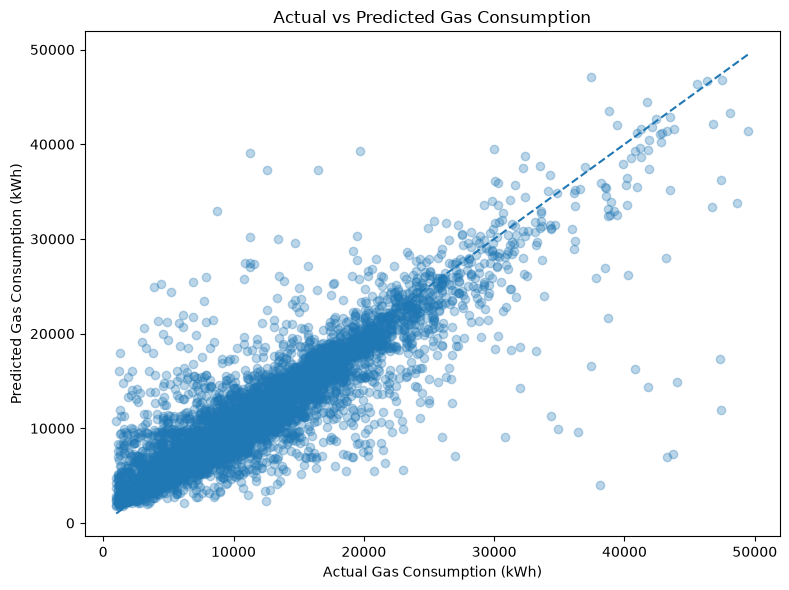

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_test_pred, alpha=0.3)

# Reference line: perfect predictions
min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Gas Consumption (kWh)")
plt.ylabel("Predicted Gas Consumption (kWh)")
plt.title("Actual vs Predicted Gas Consumption")
plt.tight_layout()

plt.savefig("../figures/actual_vs_predicted.png", dpi=300)
plt.show()

### Step 14 — Residual Analysis

A residual is the difference between actual and predicted gas consumption. Residual analysis helps identify systematic prediction errors and properties for which the model performs poorly.

* Positive residual: the model underpredicted consumption.
* Negative residual: the model overpredicted consumption.


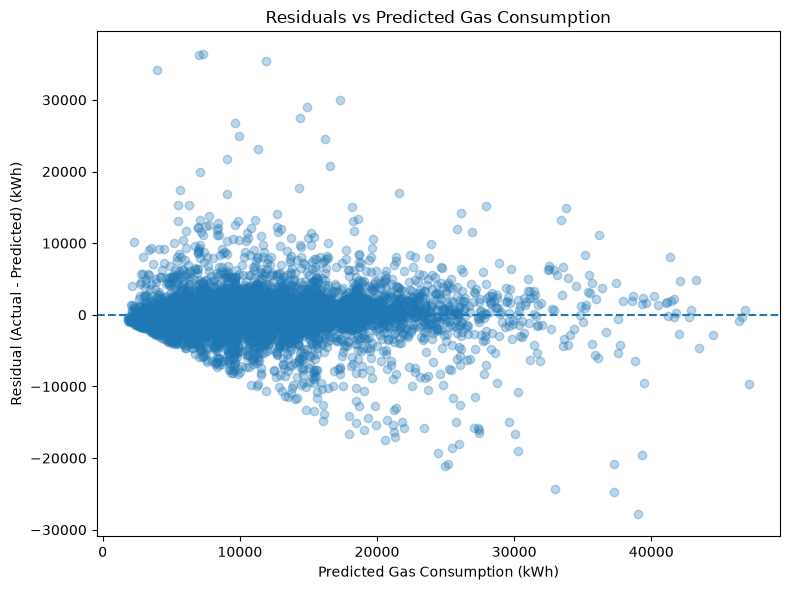

In [17]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_test_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Gas Consumption (kWh)")
plt.ylabel("Residual (Actual - Predicted) (kWh)")
plt.title("Residuals vs Predicted Gas Consumption")
plt.tight_layout()

plt.savefig("../figures/residuals_vs_predicted.png", dpi=300)
plt.show()

### Step 15 — Feature Importance

Feature importance helps us understand which input variables the trained Random Forest uses most when making predictions. This analysis provides insight into the factors associated with predicted gas consumption, but it does not establish causation.


In [18]:
# Get the preprocessing and trained Random Forest from the final pipeline
preprocessor_fitted = final_model.named_steps["preprocessor"]
rf_fitted = final_model.named_steps["model"]

# Get the names of the transformed features
feature_names = preprocessor_fitted.get_feature_names_out()

# Extract Random Forest feature importances
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_fitted.feature_importances_
})

# Display the 15 most important transformed features
importance_df = importance_df.sort_values(
    by="Importance", ascending=False
).head(15)

display(importance_df)

,Feature,Importance
0,numerical__Gcons2023,0.923093
1,numerical__Gcons2022,0.027300
2,numerical__Gcons2021,0.021169
17,categorical__FLOOR_AREA_BAND_5,0.008286
18,categorical__COUNCIL_TAX_BAND_A,0.001871
14,categorical__FLOOR_AREA_BAND_2,0.001446
9,categorical__PROP_AGE_BAND_1,0.001077
16,categorical__FLOOR_AREA_BAND_4,0.001066
33,categorical__REGION_E12000007,0.001010
24,categorical__COUNCIL_TAX_BAND_G,0.000994


### Step 16 — Visualising Feature Importance

This bar chart displays the 15 most important transformed features used by the tuned Random Forest. It helps communicate the model's reliance on historical gas consumption compared with property characteristics.


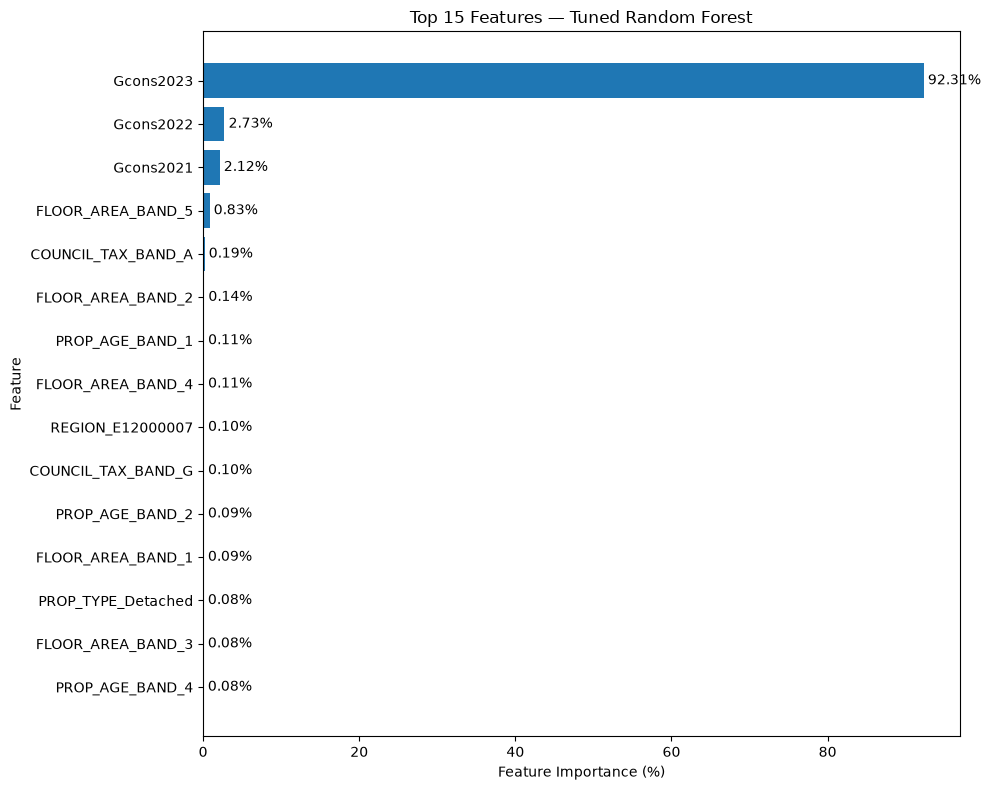

In [19]:
plot_df = importance_df.sort_values(
    by="Importance", ascending=True
).copy()

plot_df["Feature"] = (
    plot_df["Feature"]
    .str.replace("numerical__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

plt.figure(figsize=(10, 8))

bars = plt.barh(
    plot_df["Feature"],
    plot_df["Importance"] * 100
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.xlabel("Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Top 15 Features — Tuned Random Forest")
plt.tight_layout()

plt.savefig("../figures/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

### Investigating Historical Gas Consumption

We investigate whether gas consumption in 2023 is strongly correlated with gas consumption in 2024. We also compare it with consumption in 2022 and 2021 to understand how the relationship changes over time.

Pearson correlation measures the strength of a linear relationship between two numerical variables, ranging from −1 to +1.


In [20]:
# Select the target and historical gas consumption features
correlation_data = model_df[
    ["Gcons2021", "Gcons2022", "Gcons2023", "Gcons2024"]
]

# Calculate pairwise Pearson correlations
correlation_matrix = correlation_data.corr()

# Display correlations with the target
target_correlations = (
    correlation_matrix["Gcons2024"]
    .drop("Gcons2024")
    .sort_values(ascending=False)
)

display(target_correlations)

Gcons2023    0.889550
Gcons2022    0.821136
Gcons2021    0.777474
Name: Gcons2024, dtype: float64

### 2023 vs 2024 Gas Consumption

This scatter plot investigates the relationship between historical and subsequent annual gas consumption. Each point represents a property with available consumption data for both years.


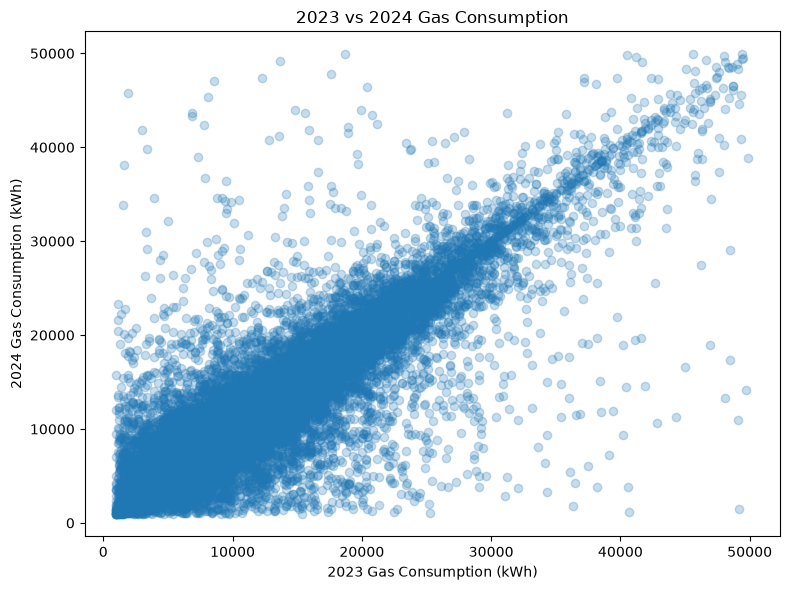

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    model_df["Gcons2023"],
    model_df["Gcons2024"],
    alpha=0.25
)

plt.xlabel("2023 Gas Consumption (kWh)")
plt.ylabel("2024 Gas Consumption (kWh)")
plt.title("2023 vs 2024 Gas Consumption")

plt.tight_layout()
plt.savefig("../figures/gas_consumption_correlation.png", dpi=300)
plt.show()

### Experiment — Previous-Year Baseline vs Full Model

Because 2023 gas consumption has a strong correlation with 2024 consumption, we compare a simple previous-year prediction against our tuned Random Forest. This experiment measures whether the full model improves prediction accuracy beyond carrying forward the previous year's consumption.


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use only test properties with observed 2023 consumption
has_previous_year = X_test["Gcons2023"].notna()

y_test_comparison = y_test.loc[has_previous_year]
previous_year_pred = X_test.loc[has_previous_year, "Gcons2023"]

# Full model predictions for those same properties
full_model_pred = final_model.predict(
    X_test.loc[has_previous_year]
)

comparison = pd.DataFrame({
    "Model": [
        "Previous-year baseline",
        "Tuned Random Forest"
    ],
    "MAE (kWh)": [
        mean_absolute_error(y_test_comparison, previous_year_pred),
        mean_absolute_error(y_test_comparison, full_model_pred)
    ],
    "RMSE (kWh)": [
        np.sqrt(mean_squared_error(y_test_comparison, previous_year_pred)),
        np.sqrt(mean_squared_error(y_test_comparison, full_model_pred))
    ]
})

display(comparison.round(2))

print(f"Test properties compared: {len(y_test_comparison)}")

,Model,MAE (kWh),RMSE (kWh)
0,Previous-year baseline,1684.92,3117.82
1,Tuned Random Forest,1716.41,2976.03


Test properties compared: 7794


### Previous-Year Baseline vs Tuned Random Forest

The previous-year baseline achieved a test MAE of 1,684.92 kWh and RMSE of 3,117.82 kWh. The tuned Random Forest achieved a test MAE of 1,716.41 kWh and RMSE of 2,976.03 kWh on the same 7,794 properties.

The previous-year baseline performed better in terms of MAE, while the Random Forest achieved a lower RMSE. This indicates that the more complex model did not improve average absolute prediction error, although it reduced the overall penalty associated with larger errors.

The results demonstrate the importance of comparing machine-learning models against simple, meaningful baselines rather than assuming that a more complex model will perform better.


### Experiment — Histogram-Based Gradient Boosting

We train a Gradient Boosting regression model to predict 2024 residential gas consumption. Unlike Random Forest, which combines many independently trained trees, Gradient Boosting builds trees sequentially, with each new tree attempting to improve the predictions made by the existing ensemble.

We evaluate the model using the same five-fold cross-validation strategy as our previous models. All preprocessing remains inside the pipeline to prevent data leakage.


In [23]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

gradient_boosting_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    ))
])

gb_scores = cross_val_score(
    gradient_boosting_model,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

gb_mae_scores = -gb_scores

print("Gradient Boosting CV MAE by fold:")
print(gb_mae_scores.round(2))

print(f"\nMean CV MAE: {gb_mae_scores.mean():.2f} kWh")
print(f"CV MAE standard deviation: {gb_mae_scores.std():.2f} kWh")

Gradient Boosting CV MAE by fold:
[1767.53 1763.57 1732.91 1745.77 1785.62]

Mean CV MAE: 1759.08 kWh
CV MAE standard deviation: 18.21 kWh


In [24]:
from sklearn.model_selection import GridSearchCV

gb_param_grid = {
    "model__max_iter": [200, 300],
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31]
}

gb_grid_search = GridSearchCV(
    estimator=gradient_boosting_model,
    param_grid=gb_param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

print("Best parameters:")
print(gb_grid_search.best_params_)

print(f"\nBest CV MAE: {-gb_grid_search.best_score_:.2f} kWh")

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters:
{'model__learning_rate': 0.05, 'model__max_iter': 200, 'model__max_leaf_nodes': 15}

Best CV MAE: 1756.12 kWh


### Tuned Gradient Boosting Model

The `HistGradientBoostingRegressor` was tuned using GridSearchCV with five-fold cross-validation. The search evaluated eight hyperparameter combinations, resulting in 40 model fits.

The best configuration was:

* `learning_rate`: 0.05
* `max_iter`: 200
* `max_leaf_nodes`: 15

The best cross-validation MAE was **1,756.12 kWh**. This was slightly higher than the tuned Random Forest's MAE of 1,749.20 kWh. Therefore, the tuned Random Forest remains the leading candidate based on cross-validation performance.
